Shape of X:  (500, 2)
Correlation:  0.6992223066425663

Mean:
[ 2.1523992  -0.93464455]

Covariance matrix:
[[2.91615571 1.1656626 ]
 [1.1656626  0.95302538]]

Eigenvalues:
[3.45848013 0.41070096]

Principal components:
[[-0.90667478  0.42183036]
 [-0.42183036 -0.90667478]]

Explained variance fractions:
[0.89385326 0.10614674]

Explained variance percentages:
[89.38532602 10.61467398]

Question 2: There is a positive linear relationship between Feature 1 and Feature 2. 
When Feature 1 is larger, Feature 2 also tends to be larger.  
This is because the covariance is positive. The correlation is also positive.

Question 4: PC1 makes up about 89% of variance while PC2 makes up about 11% of variance. 
We can keep only PC1 and have one dimension rather than two. 
The tradeoff is that 11% of variance is discarded. 
With PCA we can preserve most of the varience of the data and have a lower dimensional representation


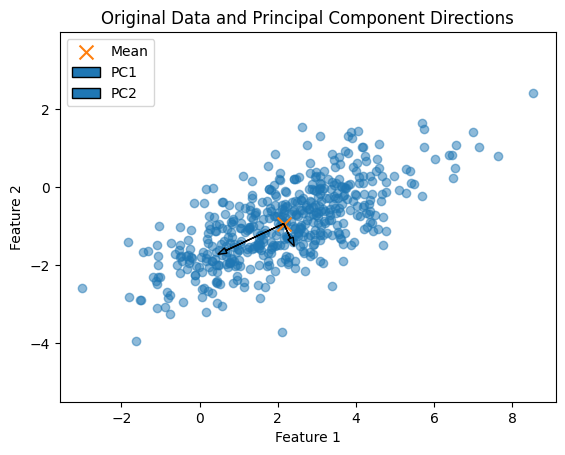

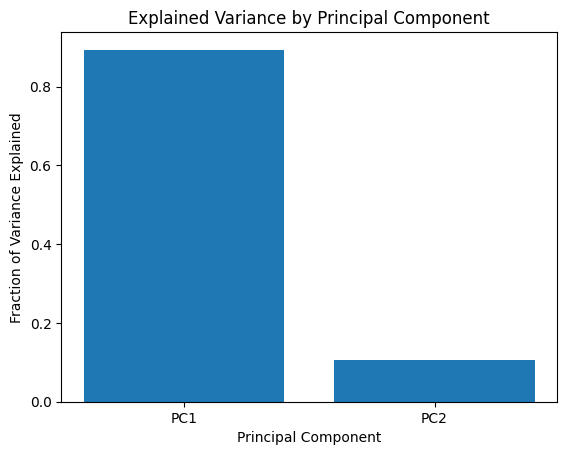

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# P3 Q2: Describe the Gaussian generator and observed correlation.
# YOUR ANSWER HERE
def generate_data(n_samples=500, seed=0, mean=None, covariance=None):
    """Return reproducible Gaussian samples (n_samples,2) using NumPy and seed.

    Defaults: mean=[2,-1], covariance=[[3,1.2],[1.2,1]]. Custom mean has shape
    (2,), covariance (2,2) is positive definite. Do not mutate input arrays.
    """
    #if the mean is not provided, use default
    #Feature 1 is centered around 2 and Feature 2 is centered around -1
    if mean is None:
      mean = np.array([2,-1])
    else:
      #makes a copy of a provided mean so we do not modify the original array
      mean = np.array(mean, copy=True)

    #If the covariance matrix is not provided, use the default
    #The positive offdiaganol values mean the two features tend to increase together
    #This creates a positive correlation
    if covariance is None:
      covariance = np.array([[3,1.2], [1.2,1]])
    else:
      #Make a copy so we do not modify the original covariance matrix
      covariance = np.array(covariance, copy=True)

    #Generate a random number using the given seed.
    #Using the same seed gives us the same random number each time
    rng = np.random.default_rng(seed)
    #Generate n_samples points from a 2-dimensional Gaussian distribution
    #The result has the shape (n_samples,2)
    #each row is a data point, column0=feature1, column1=feature2
    X = rng.multivariate_normal(mean, covariance, n_samples)
    return X

# P3 Q3: Link centering/covariance/eigendecomposition to the derivation and explain the plot.
# YOUR ANSWER HERE
def pca(X):
    """Fit NumPy PCA without mutating finite X of shape (n,2), n>=2.

    Return dict: mean (2,), centered (n,2), covariance (2,2), eigenvalues (2,),
    components (2,2), scores (n,2). Use covariance divisor n-1, descending
    eigenvalues, orthonormal eigenvectors as columns, scores=centered@components.
    Signs/tied-eigenspace bases are free. Include rank-deficient and tied cases.
    NumPy eigh/SVD are allowed; fitted library PCA is not.
    """
    #find the mean of each feature, mean[0] is mean of feature 1, and mean[2] is mean of feature 2
    #This corresponds to E[X]
    #axis = 0 means calculate down each column
    mean = np.mean(X, axis=0)
    #subtract the mean of each feature from every data point
    #X_centered = X - E[X]
    #Create a new array to avoid mutating the original dataset
    centered = X - mean
    #The covariance matrix tells us how the 2 features vary with respect to eachother
    #rowvar=False tells the function that the columns are variables/features and the rows are observations/data points
    #np.cov uses n-1 as the divisor by default
    covariance = np.cov(centered, rowvar=False)
    #PCA finds the directions where the data has the most variance..
    #The eigenvectors give us the direcctions (AKA principal components)
    #The eigenvalues tell us how much variance exists in each of those directions
    #np.linalg.eigh returns eigenvalues from smallest to largest, so we have to fix that
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    #PCA defines PC1 as the direction having the largest eigenvalue anbd PC2 as the direction with the second-largest
    #np.argsort gives the indices that would sort the values, [::-1] reverses the order so that its descending
    order = np.argsort(eigenvalues)[::-1]
    #reorder eigenvalues with those indices
    eigenvalues = eigenvalues[order]
    #reorder eigenvectors with those indices
    # ":" = keep all rows, since each eigenvector must stay matches with its corresponding eigenvalue
    # "order" tells it to reorder the columns
    eigenvectors = eigenvectors[:, order]
    #The eigenvectors ARE the PC directions
    components = eigenvectors
    #Multiply the centered data by the principal component directions: scores = centered * components
    #This projects each data point onto the PC1 and PC2 directions
    #each row is one data point, but its coordinates are expressed in PC component directions
    scores = centered@components
    return {
        "mean": mean,
        "centered": centered,
        "covariance": covariance,
        "eigenvalues": eigenvalues,
        "components": eigenvectors,
        "scores": scores
    }


# P3 Q4: Interpret the variance fractions and dimensionality reduction tradeoff.
# YOUR ANSWER HERE
def explained_variance(eigenvalues):
    """Return same-shape fractions for nonnegative eigenvalues with positive sum."""
    #Add all the eigenvalues together
    #eigenvalues represent the variance captured by each PC, so their sum is the total variance
    total = np.sum(eigenvalues)
    #divide EACH eigenvalue by the TOTAL variance
    #This tells us what fraction of the total variance is explained by each PC
    return eigenvalues/total


# P3 Q2/Q3/Q4: Provide labeled figures and discuss their meaning.
# YOUR ANSWER HERE
def make_plots(X, result):
    """Return a Matplotlib Figure (or sequence of Figures), without show/save.

    Plot samples and principal directions through their mean, and explained
    variance fractions. Label axes. Plot quality is manually reviewed.
    """
    mean = result["mean"]
    eigenvalues = result["eigenvalues"]
    components = result["components"]

    fractions = explained_variance(eigenvalues)

    fig1, ax1 = plt.subplots()
    ax1.scatter(X[:, 0], X[:, 1], alpha=0.5)
    ax1.scatter(
        mean[0],
        mean[1],
        marker="x",
        s=100,
        label="Mean"
    )

    for i in range(2):
        direction = components[:, i]

        ax1.arrow(
            mean[0],
            mean[1],
            direction[0] * np.sqrt(eigenvalues[i]),
            direction[1] * np.sqrt(eigenvalues[i]),
            head_width=0.15,
            length_includes_head=True,
            label=f"PC{i+1}"
        )

    ax1.set_xlabel("Feature 1")
    ax1.set_ylabel("Feature 2")
    ax1.set_title("Original Data and Principal Component Directions")
    ax1.legend()
    ax1.axis("equal")

    fig2, ax2 = plt.subplots()

    ax2.bar(["PC1", "PC2"], fractions)

    ax2.set_xlabel("Principal Component")
    ax2.set_ylabel("Fraction of Variance Explained")
    ax2.set_title("Explained Variance by Principal Component")

    return fig1, fig2


# REFLECTION: contributions, tasks completed, and external resources used.
# YOUR ANSWER HERE

if __name__ == '__main__':
    # YOUR CODE HERE: call your functions and save/display the requested figures.
    # This block does not run when the grader imports your functions.
    X = generate_data()
    print("Shape of X: ", X.shape)
    correlation = np.corrcoef(X[:,0], X[:,1])[0,1]
    print("Correlation: ", correlation)
    result = pca(X)
    print("\nMean:")
    print(result["mean"])
    print("\nCovariance matrix:")
    print(result["covariance"])
    print("\nEigenvalues:")
    print(result["eigenvalues"])
    print("\nPrincipal components:")
    print(result["components"])
    fractions = explained_variance(result["eigenvalues"])
    print("\nExplained variance fractions:")
    print(fractions)
    print("\nExplained variance percentages:")
    print(fractions * 100)
    figures = make_plots(X, result)
    print("\nQuestion 2: There is a positive linear relationship between Feature 1 and Feature 2. \nWhen Feature 1 is larger, Feature 2 also tends to be larger.  \nThis is because the covariance is positive. The correlation is also positive.")
    print("\nQuestion 4: PC1 makes up about 89% of variance while PC2 makes up about 11% of variance. \nWe can keep only PC1 and have one dimension rather than two. \nThe tradeoff is that 11% of variance is discarded. \nWith PCA we can preserve most of the varience of the data and have a lower dimensional representation")
    for fig in figures:
      plt.show()
    pass